In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv('data.csv')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6819 entries, 0 to 6818
Data columns (total 96 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   Bankrupt?                                                 6819 non-null   int64  
 1    ROA(C) before interest and depreciation before interest  6819 non-null   float64
 2    ROA(A) before interest and % after tax                   6819 non-null   float64
 3    ROA(B) before interest and depreciation after tax        6819 non-null   float64
 4    Operating Gross Margin                                   6819 non-null   float64
 5    Realized Sales Gross Margin                              6819 non-null   float64
 6    Operating Profit Rate                                    6819 non-null   float64
 7    Pre-tax net Interest Rate                                6819 non-null   float64
 8    After-tax net Int

In [ ]:
np.shape(df)

(6819, 96)

In [ ]:
# import train_test_split and cross validation
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_predict

In [ ]:
from sklearn import preprocessing

In [ ]:
df=df.to_numpy()

In [ ]:
df

array([[1.        , 0.37059426, 0.42438945, ..., 0.56405011, 1.        ,
        0.01646874],
       [1.        , 0.46429094, 0.53821413, ..., 0.57017495, 1.        ,
        0.02079431],
       [1.        , 0.42607127, 0.49901875, ..., 0.56370608, 1.        ,
        0.01647411],
       ...,
       [0.        , 0.47272461, 0.533744  , ..., 0.5651584 , 1.        ,
        0.09764874],
       [0.        , 0.50626432, 0.5599106 , ..., 0.56530151, 1.        ,
        0.04400945],
       [0.        , 0.49305319, 0.57010467, ..., 0.56516694, 1.        ,
        0.23390224]])

In [ ]:
df=np.transpose(df)

In [ ]:
y = np.transpose(df[0])
X = np.transpose(df[1:])

In [ ]:
np.shape(X),np.shape(y)

((6819, 95), (6819,))

In [ ]:
#Count the features that have no difference at all in all data
np.shape(X)[1]-np.count_nonzero(np.std(X,axis=0))

1

In [ ]:
#Find the index of feature which have no difference at all
np.min(np.std(X,axis=0)), np.where(np.std(X,axis=0)==0), np.argmin(np.std(X,axis=0))

(0.0, (array([93]),), 93)

In [ ]:
check_feature_name_with_sd_0=[]

In [ ]:
for i in range(np.shape(np.where(np.std(X,axis=0)==0))[0]):
  print(pd.read_csv('data.csv').columns.tolist()[(list(np.where(np.std(X,axis=0)==0)[i])[0])+1])

 Net Income Flag


In [ ]:
X=np.delete(X,list(np.where(np.std(X,axis=0)==0)),axis=1)

In [ ]:
#Count the features that have no difference at all in all data after deleting the data
np.shape(X)[1]-np.count_nonzero(np.std(X,axis=0))

0

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
X_train, X_train_val, y_train, y_train_val = train_test_split(X_train, y_train, test_size=0.15, random_state=0)

In [ ]:
np.shape(X_train),np.shape(y_train),np.shape(X_test),np.shape(y_test)

((4636, 94), (4636,), (1364, 94), (1364,))

In [ ]:
np.shape(X_train_val),np.shape(y_train_val)

((819, 94), (819,))

In [ ]:
np.shape(np.mean(X_train,axis=0))

(94,)

In [ ]:
np.count_nonzero(np.std(X,axis=0))

94

In [ ]:
mean=np.copy(np.mean(X_train,axis=0))
std=np.copy(np.std(X_train,axis=0))

In [ ]:
X_train_rescale=(X_train-mean)/(std)

In [ ]:
X_train_rescale

array([[ 1.90296242,  1.75119366,  1.86826578, ..., -0.04482293,
        -0.0121836 , -0.42214359],
       [ 0.6281232 ,  0.28436509,  0.77600121, ..., -0.0377838 ,
         0.03174293, -0.38983898],
       [-0.09873029, -0.31695914, -0.10257863, ..., -0.02571204,
         0.08874173, -0.36849753],
       ...,
       [ 0.01346857,  0.23656108,  0.0457645 , ..., -0.03814377,
         0.02972356, -0.33827418],
       [-0.49061327, -0.26663912, -0.43193569, ..., -0.03723269,
         0.03479245, -0.30907101],
       [ 0.35087819,  0.39506914,  0.47489998, ..., -0.04117001,
         0.0118357 , -0.29664792]])

In [ ]:
#Check all value is not NaN, -infity or infinity
np.isfinite(X_train_rescale).all()

True

In [ ]:
X_train_new_rescale=np.copy(X_train_rescale[(abs(X_train_rescale)<3.5).all(axis=1)])
#Even y_train_new_rescale is called y_train_new_rescale, we did not rescale it.
#We just remove the outliers according to X_train
y_train_new_rescale=np.copy(y_train[(abs(X_train_rescale)<3.5).all(axis=1)])

In [ ]:
np.shape(X_train_new_rescale), np.shape(y_train_new_rescale)

((3716, 94), (3716,))

In [ ]:
np.shape(np.min(X_train_new_rescale,axis=0))

(94,)

In [ ]:
import sklearn
from sklearn import preprocessing

In [ ]:
scaler = preprocessing.StandardScaler().fit(X_train_new_rescale)

In [ ]:
X_train_new_rescale=scaler.transform(X_train_new_rescale)

In [ ]:
X_train_new_rescale

array([[ 2.22267222,  2.15271734,  2.2175063 , ..., -0.13707927,
        -0.10647741, -0.60464602],
       [ 0.69800339,  0.29926856,  0.88484896, ..., -0.07956124,
         0.10246805, -0.5447885 ],
       [-0.50092305,  0.1795203 , -0.26466226, ..., -0.11282918,
        -0.01263509, -0.71777716],
       ...,
       [ 0.27307975,  0.30244772,  0.45283959, ..., -0.07624096,
         0.11318652,  0.1867281 ],
       [-0.63997129, -0.39696691, -0.58893862, ..., -0.07505807,
         0.11697369, -0.39513275],
       [ 0.36642682,  0.43915149,  0.5174794 , ..., -0.10723062,
         0.00777523, -0.37211388]])

In [ ]:
#Check all value is not NaN, -infity or infinity
np.isfinite(X_train_rescale).all()

True

In [ ]:
y_train_new_rescale

array([0., 0., 0., ..., 0., 0., 0.])

In [ ]:
#Show that not all the value are 0 in y_train_new_rescale
np.squeeze(np.argwhere(y_train_new_rescale==1))

array([   3,   31,   66,   95,  166,  176,  192,  280,  318,  366,  401,
        428,  451,  452,  467,  517,  537,  722,  738,  755,  763,  777,
        793,  812,  822,  840,  918,  926,  938, 1026, 1054, 1077, 1127,
       1138, 1146, 1188, 1267, 1300, 1385, 1389, 1414, 1450, 1547, 1616,
       1635, 1694, 1743, 1750, 1794, 1891, 1912, 1995, 2045, 2081, 2143,
       2150, 2167, 2178, 2236, 2317, 2363, 2455, 2504, 2535, 2592, 2601,
       2625, 2632, 2657, 2661, 2673, 2897, 2905, 2908, 2925, 2930, 2995,
       3029, 3053, 3072, 3164, 3252, 3308, 3374, 3387, 3407, 3424, 3437,
       3477, 3483, 3489, 3497, 3503, 3525, 3686, 3707])

In [ ]:
#Same rescaling in test dataset
X_test_rescale=(X_test-mean)/(std)
y_test_rescale=np.copy(y_test)

In [ ]:
#Same as the training dataset, apply twice the standardization
X_test_rescale=scaler.transform(X_test_rescale)

In [ ]:
#Check all value is not NaN, -infity or infinity
np.isfinite(X_test_rescale).all()

True

In [ ]:
#Same rescaling in validation set
X_train_val_rescale=(X_train_val-mean)/(std)
y_train_val_rescale=np.copy(y_train_val)

In [ ]:
#Same as the training dataset, apply twice the standardization
X_train_val_rescale=scaler.transform(X_train_val_rescale)

In [ ]:
#Check all value is not NaN, -infity or infinity
np.isfinite(X_train_val_rescale).all()

True

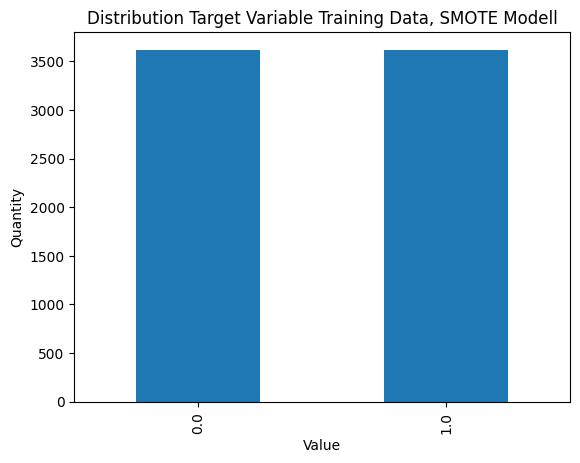

In [ ]:
#Oversampling: SMOTE Model
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train_new_rescale, y_train_new_rescale)
y_resampled_series = pd.Series(y_resampled)

value_counts = y_resampled_series.value_counts()
value_counts.plot(kind="bar")
plt.title("Distribution Target Variable Training Data, SMOTE Modell")
plt.ylabel("Quantity")
plt.xlabel("Value")
plt.show()

In [ ]:
np.shape(X_resampled),np.shape(y_resampled),np.shape(X_test_rescale),np.shape(y_test_rescale)

((7240, 94), (7240,), (1364, 94), (1364,))

In [ ]:
# import evaluation tools
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

In [ ]:
X_train_resampled=X_resampled
y_train_resampled=y_resampled

In [ ]:
np.shape(X_train_resampled),np.shape(y_train_resampled),np.shape(X_test_rescale),np.shape(y_test_rescale)

((7240, 94), (7240,), (1364, 94), (1364,))

In [ ]:
# Import Linear Regression Model from sklearn
from sklearn.linear_model import LogisticRegression

# Parameters for the logistic regression model
lm = LogisticRegression(penalty='l2', C=0.1, max_iter=1000,random_state=0, solver='lbfgs')
#https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
# Cfloat, default=1.0. Inverse of regularization strength; must be a positive float. Smaller values specify stronger regularization.
#Regularization is used to prevent overfitting, decision tree is easy  overfit.
#C is a inverse of regularization to prevent underfit.
# Parameters for the decision tree

In [ ]:
# We want to use our own validation set for GridSearchCV

In [ ]:
new_X_data=np.append(X_train_resampled, X_train_val_rescale,axis=0)

In [ ]:
np.shape(new_X_data)

(8059, 94)

In [ ]:
#Check is the first part of new_X_data are the same with the X_resampled
(new_X_data[0:np.shape(X_train_resampled)[0]]==X_train_resampled).all()

True

In [ ]:
new_y_data=np.append(y_train_resampled, y_train_val_rescale,axis=0)

In [ ]:
np.shape(new_y_data)

(8059,)

In [ ]:
#Check is the first part of new_X_data are the same with the X_resampled
(new_y_data[0:np.shape(y_resampled)[0]]==y_resampled).all()

True

In [ ]:
test_fold=[]

In [ ]:
from sklearn.model_selection import PredefinedSplit

In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
#Next part is used to separate training set and validation set
#If we do not want to use data in that index as a validation set or testing set,
#set the value to be -1 for the index
#or else, set it as number larger or equal to 0,1,2,3.
#In this example, we only want to have four validation set
#which is the validation set we splitted out from
#the unprocessed training dataset.
#because we want the model applicable on the test dataset
#which is not being oversampled or outliers removed.
#We only use 0,1,2,3 which means we only train four times by using
#those data whose labels as 0,1,2,3 as the validation set
#Example is on the words next to this block

# >>> X = np.array([[1, 2], [3, 4], [1, 2], [3, 4]])
# >>> y = np.array([0, 0, 1, 1])
# >>> test_fold = [0, 1, -1, 1]
# >>> ps = PredefinedSplit(test_fold)
# >>> ps.get_n_splits()
# 2
# >>> print(ps)
# PredefinedSplit(test_fold=array([ 0,  1, -1,  1]))
# >>> for i, (train_index, test_index) in enumerate(ps.split()):
# ...     print(f"Fold {i}:")
# ...     print(f"  Train: index={train_index}")
# ...     print(f"  Test:  index={test_index}")
# Fold 0:
#  Train: index=[1 2 3]
#  Test:  index=[0]
# Fold 1:
#  Train: index=[0 2]
#  Test:  index=[1 3]

In [ ]:
for i in range(np.shape(X_resampled)[0]):
  test_fold.append(-1)
j=0
for i in range(np.shape(X_train_val_rescale)[0]):
  test_fold.append(j)
  if j<3:
    j=j+1
  else:
    j=0

In [ ]:
ps = PredefinedSplit(test_fold=test_fold)

In [ ]:
from sklearn.model_selection import GridSearchCV

# Search for best complexity when optimizing for AUC for logistic regression
l_grid = {"C": [10**i for i in np.arange(-1, 1, 0.1)]}
l_searcher = GridSearchCV(lm, l_grid, cv=ps, scoring="roc_auc")
l_searcher.fit(new_X_data, new_y_data)

# Plot result
print(f"Best C for logsitic regression: {l_searcher.best_params_}")
print(f"Best AUC: {l_searcher.best_score_}")

Best C for logsitic regression: {'C': 0.1}
Best AUC: 0.8192925078389885


In [ ]:
lm_final = LogisticRegression(penalty='l2', C=l_searcher.best_params_['C'], max_iter=1000, solver='lbfgs')

In [ ]:
lm_final.fit(X_train_resampled,y_train_resampled)

LogisticRegression(C=0.1, max_iter=1000)

In [ ]:
lm_final.coef_

array([[-1.71188164e+00,  8.11596117e-01, -9.16422841e-02,
         1.47148299e-01,  6.09998455e-02,  9.36089483e-01,
         6.17050272e-01,  1.99427669e-01, -7.73487575e-03,
        -4.39676878e-01, -2.41317004e-01, -3.96147021e-03,
        -1.81039105e-01, -9.13219607e-02,  2.26999728e-01,
        -2.89678957e-02,  6.78531102e-02,  2.22470600e-02,
        -9.89381741e-01, -1.73400096e-01, -6.46637035e-01,
         1.69323859e-01, -4.48515907e-01, -2.21035186e-01,
        -5.55601548e-02, -4.68221937e-01,  7.50620722e-01,
        -9.34819120e-02,  1.50929164e-01,  6.91445438e-02,
         1.05957799e-01,  6.02390260e-01,  1.36743469e-01,
        -7.69709257e-01, -5.21263938e-02, -2.76969022e-01,
         3.31669245e-01, -3.31669245e-01, -5.40114613e-01,
         2.40304848e-01,  2.79018913e-01,  3.61761403e-01,
        -5.24351060e-01,  1.12849364e-01, -8.17507104e-01,
        -8.61831998e-01,  1.15586718e-04, -3.02298476e-01,
        -1.86544309e-02,  2.15095592e-01,  5.51827202e-0

In [ ]:
pred_test = lm_final.predict (X_test_rescale)
pred_test

array([0., 0., 0., ..., 0., 0., 0.])

In [ ]:
# import evaluation tools
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
print("Non-bankrupted(value=0): ",np.count_nonzero(y_train_resampled==0))
print("Bankrupted(value=1): ",np.count_nonzero(y_train_resampled))

Non-bankrupted(value=0):  3620
Bankrupted(value=1):  3620


In [ ]:
logistic_score = accuracy_score(y_test_rescale, pred_test, normalize=True, sample_weight=None)

In [ ]:
logistic_score

0.8826979472140762

In [ ]:
logistic_preds = pred_test

In [ ]:
print (f'This is prediction for decision tree: \n {logistic_preds}')

This is prediction for decision tree: 
 [0. 0. 0. ... 0. 0. 0.]


In [ ]:
np.count_nonzero(logistic_preds==0),np.count_nonzero(logistic_preds)

(1190, 174)

In [ ]:
print(f'This is confusion matrix for logistic regression: \n{confusion_matrix(y_test_rescale, logistic_preds)}\n')

This is confusion matrix for logistic regression: 
[[1174  144]
 [  16   30]]



In [ ]:
logistic_preds_prob = lm_final.predict_proba(X_test_rescale)

In [ ]:
logistic_preds_prob

array([[9.92891488e-01, 7.10851194e-03],
       [8.89056420e-01, 1.10943580e-01],
       [9.99138285e-01, 8.61714715e-04],
       ...,
       [9.98807691e-01, 1.19230865e-03],
       [1.00000000e+00, 0.00000000e+00],
       [9.98624585e-01, 1.37541494e-03]])

In [ ]:
logistic_preds_prob_1 = lm_final.predict_proba(X_test_rescale)[:,1]

In [ ]:
logistic_fpr, logistic_tpr, thresholds = roc_curve(y_test_rescale, logistic_preds_prob_1)

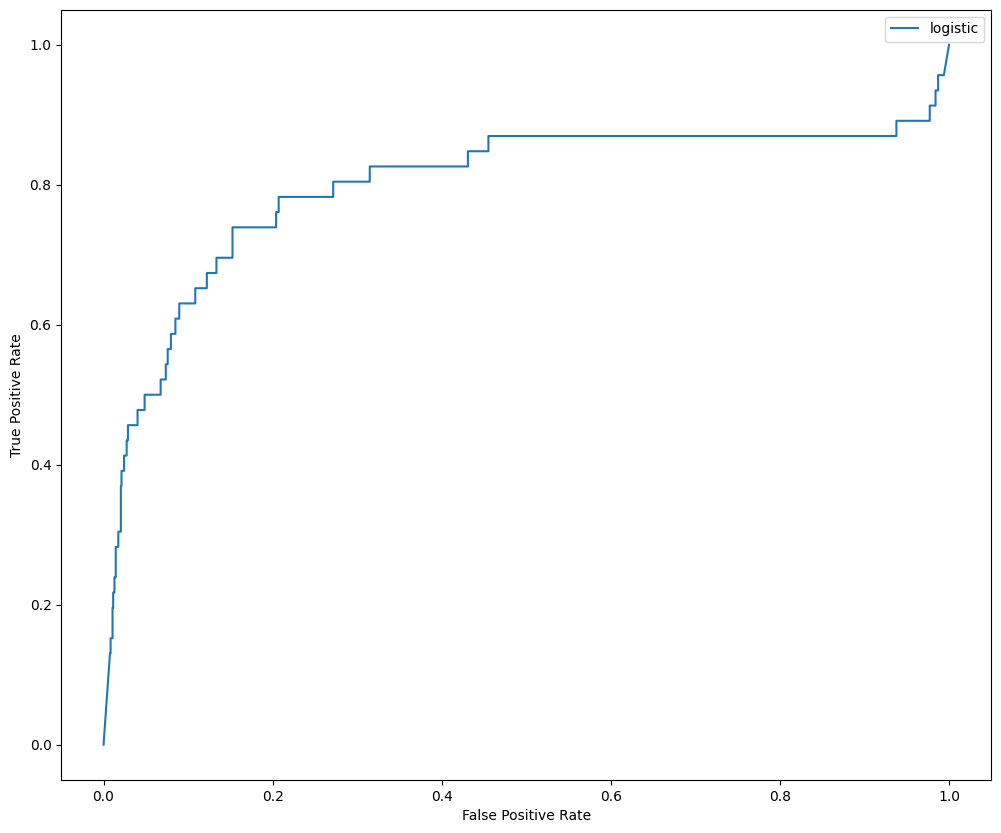

In [ ]:
# Plot the ROC curves
plt.figure(figsize=(12, 10))
plt.plot(logistic_fpr, logistic_tpr, label="logistic")
plt.legend()
plt.ylabel("True Positive Rate")
plt.xlabel("False Positive Rate")
plt.show()

In [ ]:
from sklearn.metrics import auc

# Get AUC
logistic_auc = auc(logistic_fpr, logistic_tpr)

# Print results
pd.DataFrame({"Model":['Logistic Regression'], "AUC":[logistic_auc]})

,Model,AUC
0,Logistic Regression,0.798278


In [ ]:
test_confusion_matrix=np.copy(confusion_matrix(y_test, logistic_preds))

In [ ]:
print("Recall=TP/(TP+FN)= ",test_confusion_matrix[1,1]/(test_confusion_matrix[1,1]+test_confusion_matrix[1,0]))

Recall=TP/(TP+FN)=  0.6521739130434783


In [ ]:
#Investor perspective: Highly aware if the company would go bankrupt
#Set the prediction threshold to be 0.15, if the probability of
#going bankrupt is larger than 15%, then it would be predictied as True.

In [ ]:
investor_prediction=np.copy(logistic_preds_prob)

In [ ]:
investor_predict_bankeuptcy=[]

In [ ]:
for i in range(np.shape(investor_prediction)[0]):
  if investor_prediction[i,1]<=0.15:
    investor_predict_bankeuptcy.append(0)
  else:
    investor_predict_bankeuptcy.append(1)

In [ ]:
print(investor_predict_bankeuptcy)

[0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 

In [ ]:
print(f'This is confusion matrix for decision tree in investor perspective: \n{confusion_matrix(y_test, investor_predict_bankeuptcy)}')

This is confusion matrix for decision tree in investor perspective: 
[[1043  275]
 [  10   36]]


In [ ]:
investor_confusion_matrix=np.copy(confusion_matrix(y_test, investor_predict_bankeuptcy))

In [ ]:
print("In investor perspective: Recall=TP/(TP+FN)= ",investor_confusion_matrix[1,1]/(investor_confusion_matrix[1,1]+investor_confusion_matrix[1,0]))

In investor perspective: Recall=TP/(TP+FN)=  0.782608695652174


In [ ]:
#We set cost as getting FP is 1, while FN is 10
#FP means investors would falsely identify a non-bankrupt company as bankrupt
#FN means investors would falsely identify a bankrupt company as non-bankrupt
#The cost of FN should be much higher than FP.
#Higher the cost, the worse it is.

In [ ]:
print("Cost:",investor_confusion_matrix[0,1]+investor_confusion_matrix[1,0]*10)

Cost: 375


In [ ]:
cost=investor_confusion_matrix[0,1]+investor_confusion_matrix[1,0]*10

In [ ]:
#We set gain of TP is 5, while TN is 0.5
#TP means investors would correctly identify a bankrupt company as bankrupt
#TN means investors would correctly identify a non-bankrupt company as non-bankrupt
#The gain of TP should be higher than TN
#In investors perspective, FP and FN should be more aware
#The value of cost should be larger than the value of gain
#because even it is non-bankrupt, it does not mean investor
#would earn a lot in that company
#Higher the gain, the better it is.

In [ ]:
print("Gain:", investor_confusion_matrix[0,0]*0.1+investor_confusion_matrix[1,1]*5)

Gain: 284.3


In [ ]:
#Net cost is used to calculate the cost including the earning when we correctly identify
#Net cost=cost-gain
#Higher the net cost, the worse it is.

In [ ]:
gain=investor_confusion_matrix[0,0]*0.1+investor_confusion_matrix[1,1]*5

In [ ]:
print("Net cost:", cost-gain)

Net cost: 90.69999999999999


In [ ]:
#Arrange the features by their coefficients

In [ ]:
sorting_attribute=np.copy(lm_final.coef_)
sorting_list=[]

In [ ]:
sorting_attribute

array([[-1.71188164e+00,  8.11596117e-01, -9.16422841e-02,
         1.47148299e-01,  6.09998455e-02,  9.36089483e-01,
         6.17050272e-01,  1.99427669e-01, -7.73487575e-03,
        -4.39676878e-01, -2.41317004e-01, -3.96147021e-03,
        -1.81039105e-01, -9.13219607e-02,  2.26999728e-01,
        -2.89678957e-02,  6.78531102e-02,  2.22470600e-02,
        -9.89381741e-01, -1.73400096e-01, -6.46637035e-01,
         1.69323859e-01, -4.48515907e-01, -2.21035186e-01,
        -5.55601548e-02, -4.68221937e-01,  7.50620722e-01,
        -9.34819120e-02,  1.50929164e-01,  6.91445438e-02,
         1.05957799e-01,  6.02390260e-01,  1.36743469e-01,
        -7.69709257e-01, -5.21263938e-02, -2.76969022e-01,
         3.31669245e-01, -3.31669245e-01, -5.40114613e-01,
         2.40304848e-01,  2.79018913e-01,  3.61761403e-01,
        -5.24351060e-01,  1.12849364e-01, -8.17507104e-01,
        -8.61831998e-01,  1.15586718e-04, -3.02298476e-01,
        -1.86544309e-02,  2.15095592e-01,  5.51827202e-0

In [ ]:
feature_name=list(pd.read_csv('data.csv'))

In [ ]:
#Remove the label feature name
feature_name=feature_name[1:]

In [ ]:
feature_name[93]

' Net Income Flag'

In [ ]:
#delete the feature that we have delete before
del feature_name[93]

In [ ]:
len(feature_name)

94

In [ ]:
#The last line in this block is to prevent the feature bing chosen again
for i in range(len(feature_name)):
  sorting_list.append(feature_name[np.argmax(sorting_attribute[0])])
  sorting_attribute[0,np.argmax(sorting_attribute)]=-100

In [ ]:
sorting_list

[' Operating Profit Rate',
 ' ROA(A) before interest and % after tax',
 ' Fixed Assets to Assets',
 ' Regular Net Profit Growth Rate',
 ' Quick Assets/Current Liability',
 ' Pre-tax net Interest Rate',
 ' Quick Assets/Total Assets',
 ' Cash Reinvestment %',
 ' Revenue per person',
 ' Cash Flow to Liability',
 ' Current Asset Turnover Rate',
 ' Cash Flow to Total Assets',
 ' Operating profit/Paid-in capital',
 ' Debt ratio %',
 ' Equity to Long-term Liability',
 ' Contingent liabilities/Net worth',
 ' Current Liability to Assets',
 ' Borrowing dependency',
 ' Tax rate (A)',
 ' Net Worth Turnover Rate (times)',
 ' Current Assets/Total Assets',
 ' Cash/Current Liability',
 ' After-tax net Interest Rate',
 ' Total assets to GNP price',
 ' Current Liabilities/Liability',
 ' Current Liability to Liability',
 ' Operating Profit Per Share (Yuan ¥)',
 ' Total Asset Growth Rate',
 ' Operating Gross Margin',
 ' Gross Profit to Sales',
 ' Current Ratio',
 ' Inventory and accounts receivable/Net va